# Multi-Class Benchmark Classification Pipeline (Iris / Wine)
### Task 1: End-to-End Supervised Machine Learning Pipeline with Scikit-Learn

This Jupyter Notebook implements a complete, production-ready supervised classification pipeline covering:
1. **Dataset Loading**: Ingest benchmark datasets (Iris & Wine) using Pandas.
2. **Exploratory Data Analysis (EDA)**: Statistical summaries & Seaborn exploratory **pairplots**.
3. **Train/Test Splitting**: Stratified 80/20 train/test partition (`random_state=42`).
4. **Feature Normalization**: Standardization via `StandardScaler()`, preventing data leakage by fitting strictly on training sets.
5. **Model Training**: **Multinomial Logistic Regression** and **Decision Tree Classifier**.
6. **Benchmarking Metrics**: Multi-class Accuracy, Precision (macro & weighted), Recall (macro & weighted), F1-Score, and complete Classification Reports.
7. **Visualizations**:
   - Plotted **Confusion Matrix Heatmaps** side-by-side.
   - Plotted **Decision Boundary Visualizations** comparing linear decision surfaces against orthogonal tree partitions in 2D Feature Space and PCA Space.

In [1]:
# System and Machine Learning Libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn modules
from sklearn.datasets import load_iris, load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.decomposition import PCA
from matplotlib.colors import ListedColormap

# Plotting configuration
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.dpi'] = 110
%matplotlib inline

print("✅ All required libraries imported successfully.")

✅ All required libraries imported successfully.


## Step 1: Load Benchmark Dataset Using Pandas
We load the **Fisher's Iris dataset** from CSV into a Pandas DataFrame. We inspect columns, dimensions, sample records, and class balance.

In [2]:
# Load Iris benchmark dataset via Pandas
df_iris = pd.read_csv('data/iris.csv')

# Separate features and target
feature_cols = [c for c in df_iris.columns if c not in ['species_id', 'species']]
target_col = 'species'
target_classes = ['setosa', 'versicolor', 'virginica']

print(f"Dataset Dimensions: {df_iris.shape[0]} samples x {df_iris.shape[1]} columns")
print(f"Feature Columns ({len(feature_cols)}): {feature_cols}")
print(f"Target Column: '{target_col}' with classes: {target_classes}\n")
df_iris.head()

Dataset Dimensions: 150 samples x 6 columns
Feature Columns (4): ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target Column: 'species' with classes: ['setosa', 'versicolor', 'virginica']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species_id,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [3]:
# Statistical profiling and class distribution
print("=== Target Class Distribution ===")
print(df_iris['species'].value_counts())

print("\n=== Summary Statistics ===")
df_iris[feature_cols].describe()

=== Target Class Distribution ===
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

=== Summary Statistics ===


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


## Step 2: Exploratory Pairplots with Seaborn
We generate a pairwise feature scatter grid colored by species. The diagonal depicts kernel density estimations (KDE). This visually reveals that *Iris-setosa* is linearly separable based on petal dimensions, while *versicolor* and *virginica* exhibit mild overlap.

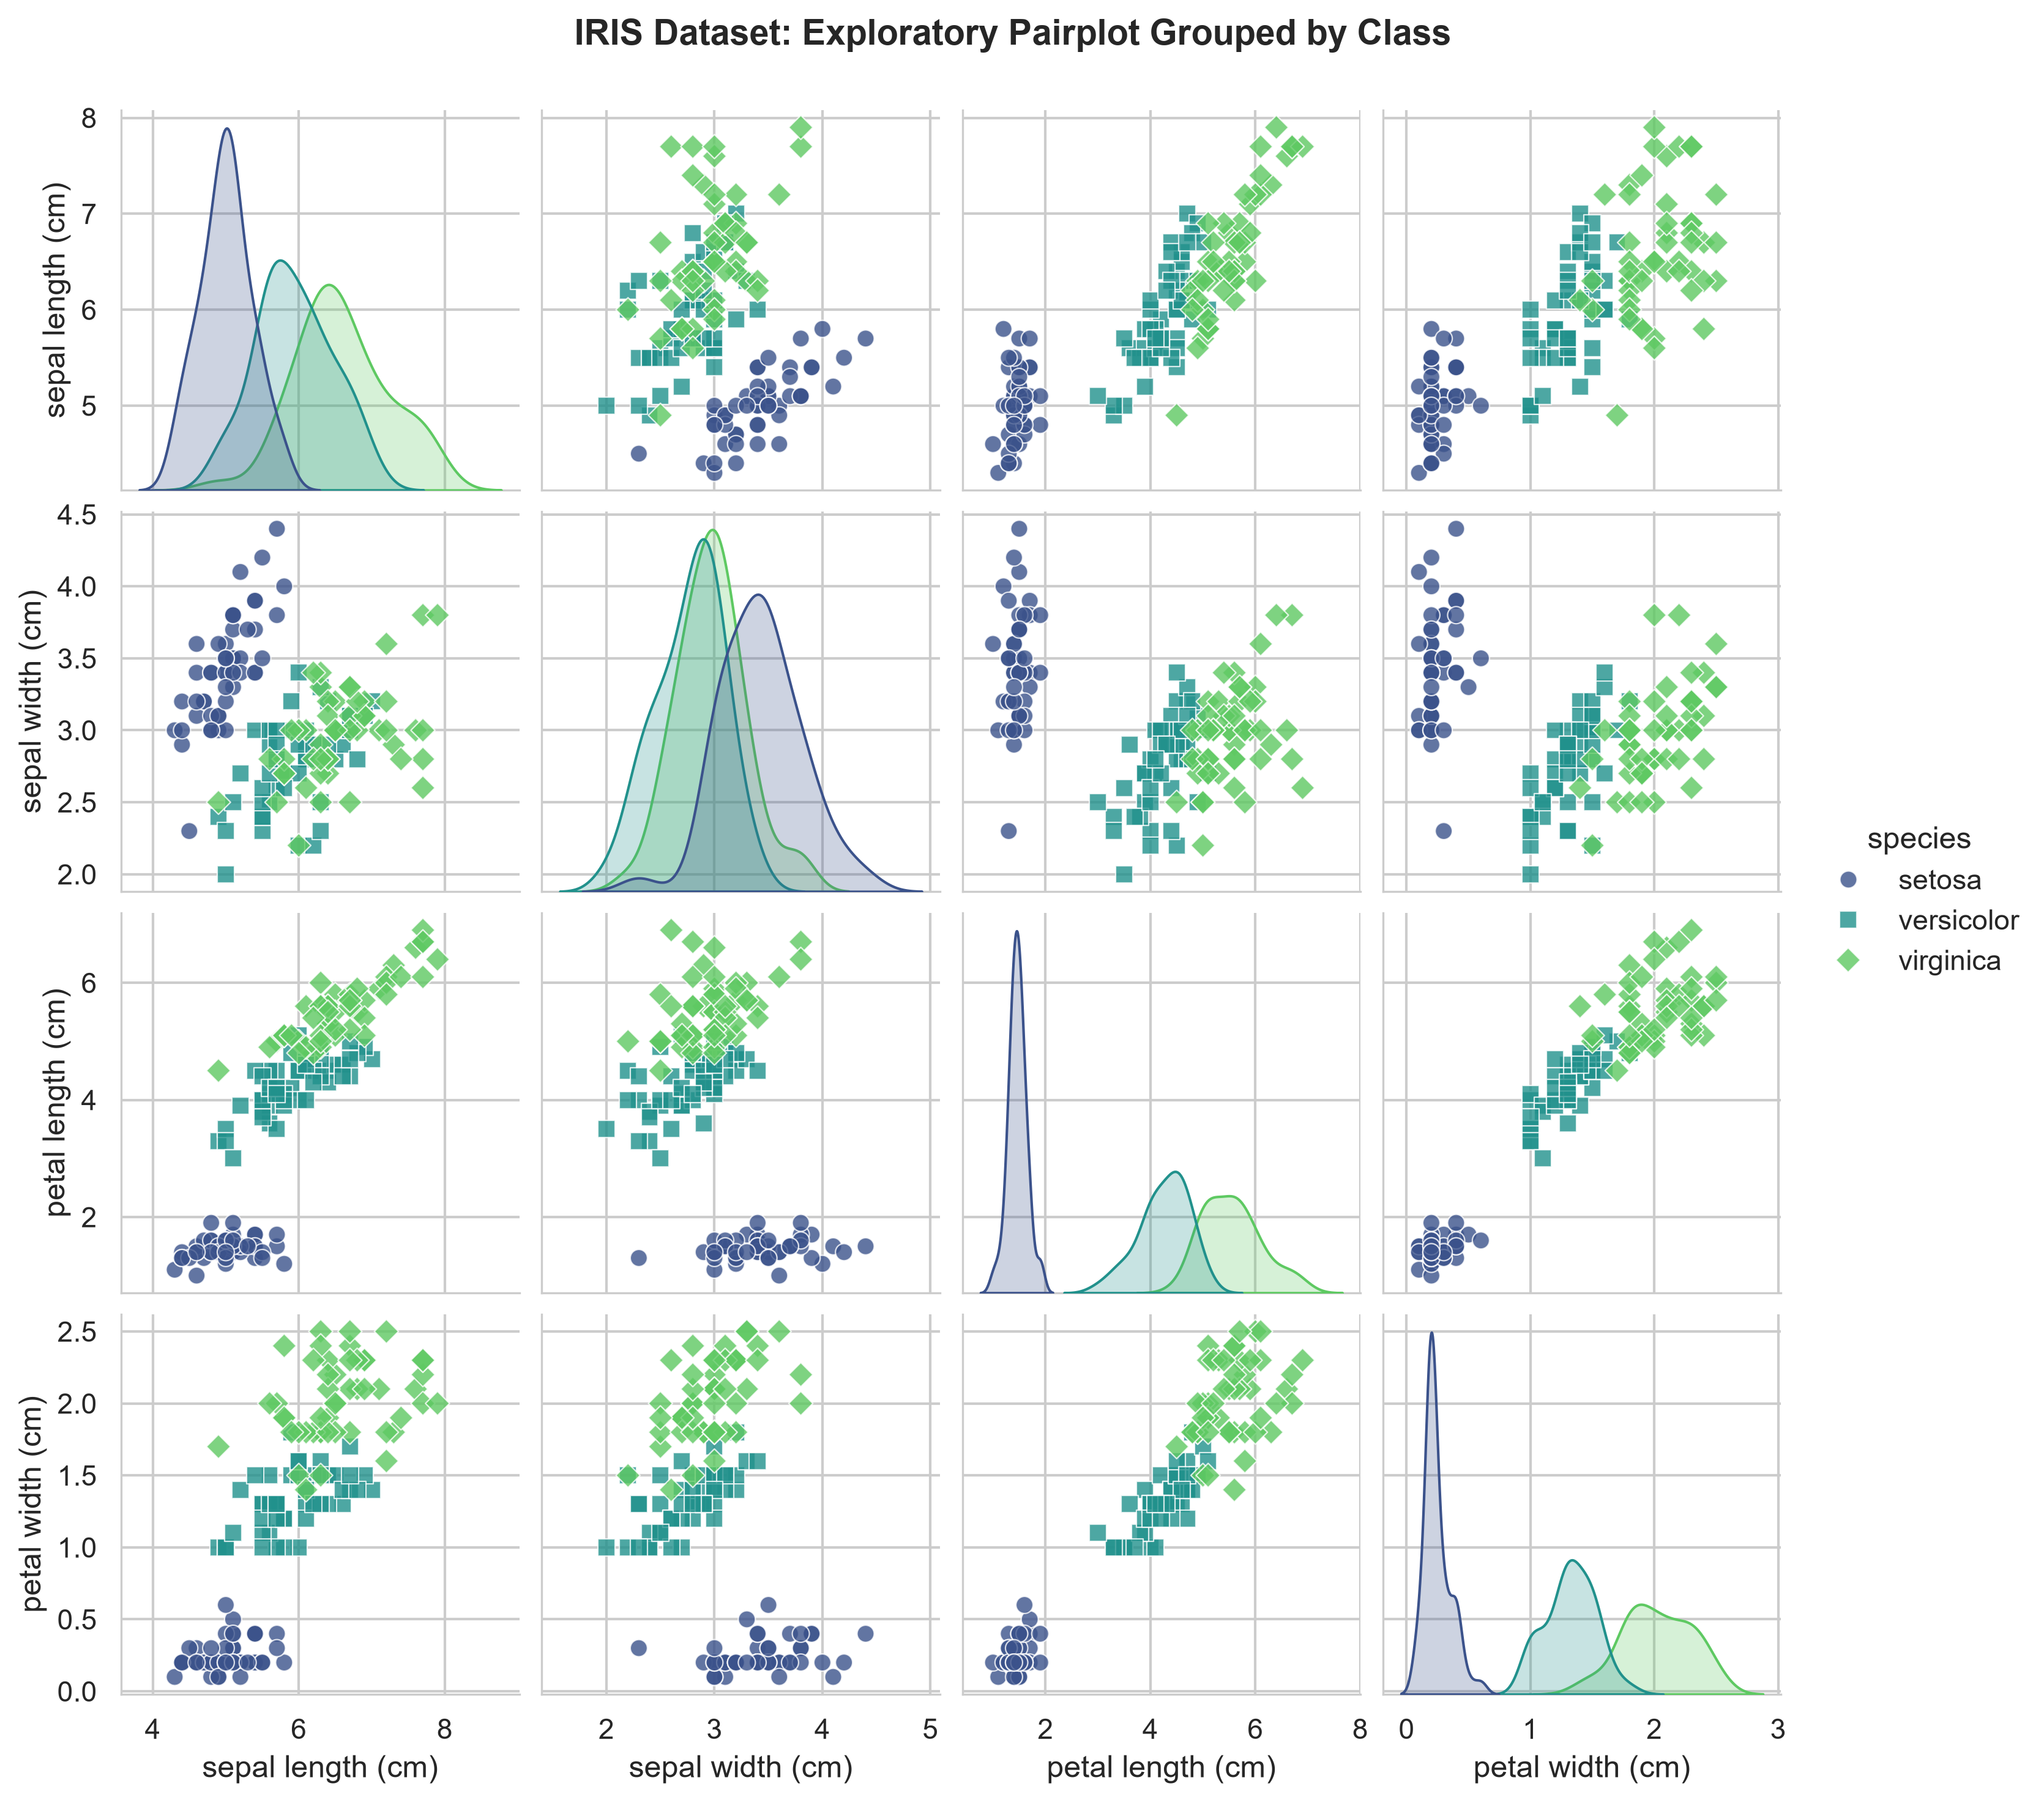

In [4]:
# Exploratory pairplot with Seaborn
pairplot = sns.pairplot(
    df_iris[feature_cols + ['species']],
    hue='species',
    diag_kind='kde',
    palette='viridis',
    markers=["o", "s", "D"],
    plot_kws={'alpha': 0.8, 's': 45}
)
pairplot.fig.subplots_adjust(top=0.93)
pairplot.fig.suptitle("Iris Dataset: Pairplot of Features by Species", fontsize=14, fontweight='bold')
plt.show()

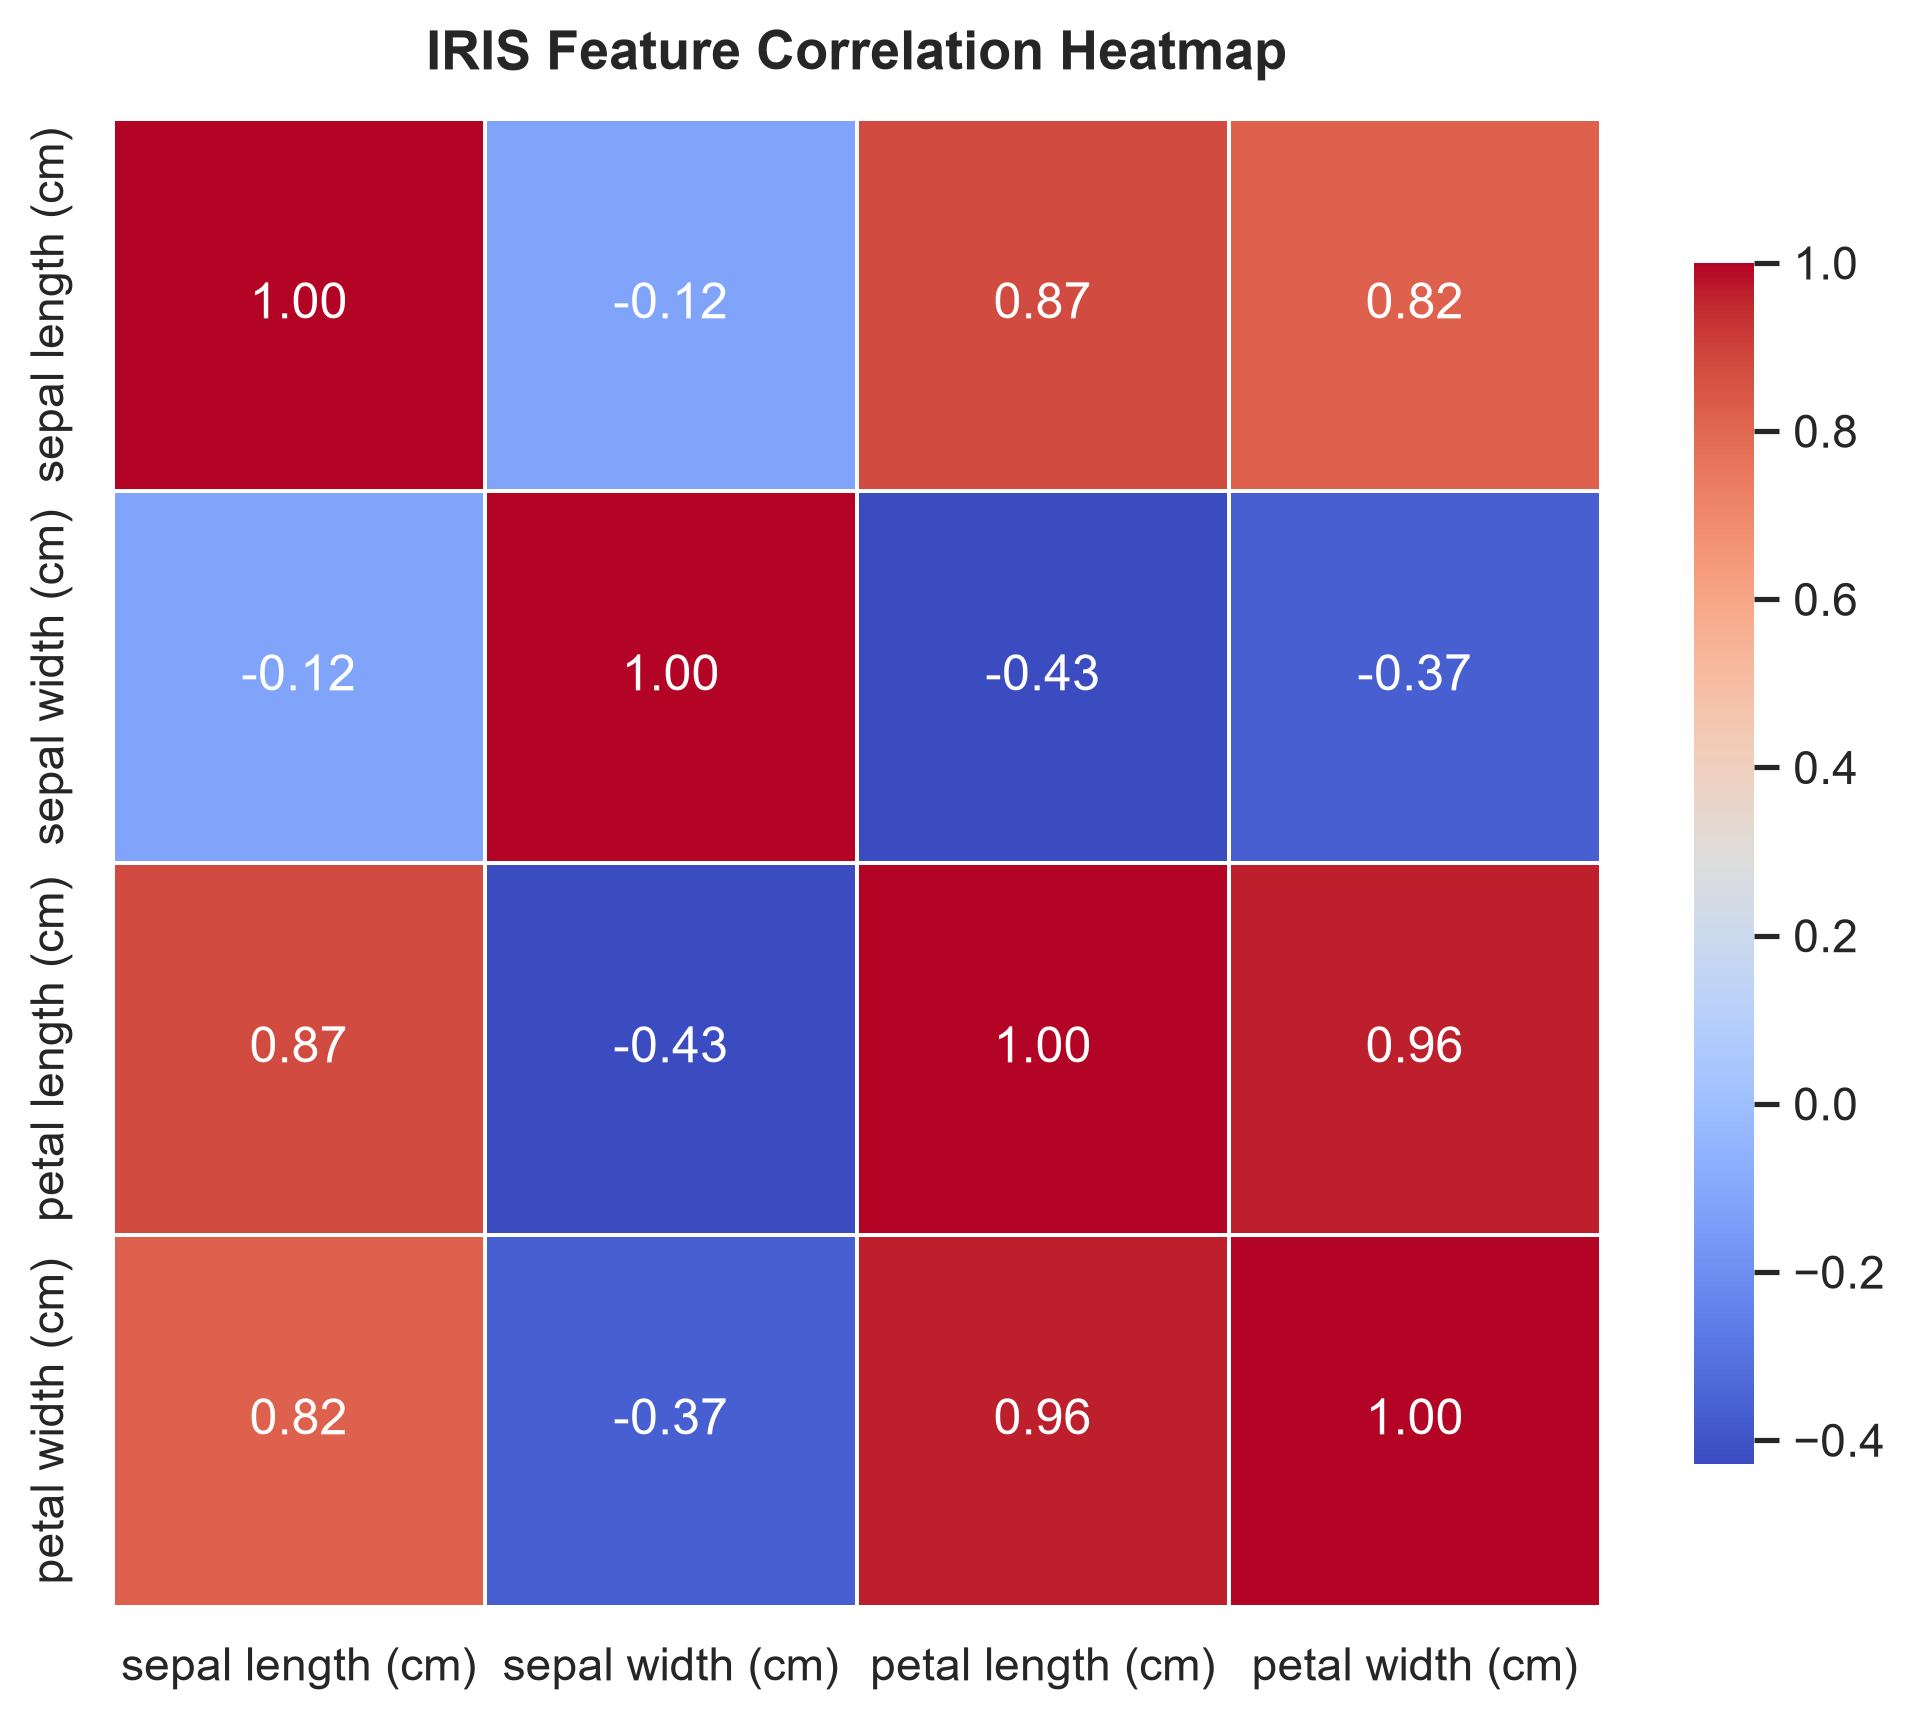

In [5]:
# Feature Correlation Heatmap
plt.figure(figsize=(7, 5))
corr = df_iris[feature_cols].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=True, linewidths=0.8, cbar_kws={"shrink": 0.8})
plt.title("Iris Feature Correlation Matrix", fontsize=13, fontweight='bold', pad=12)
plt.show()

## Step 3: Train/Test Splitting (80/20) and Feature Scaling (StandardScaler)

### Key Principles:
1. **Stratification**: Guarantees identical proportions of each species in both train (80%) and test (20%) sets.
2. **Avoiding Data Leakage**: `StandardScaler()` is **fitted solely on the training data** (`scaler.fit_transform(X_train)`), and the computed means ($\mu$) and standard deviations ($\sigma$) are subsequently applied to transform test samples (`scaler.transform(X_test)`).

In [6]:
# Convert to NumPy arrays
X = np.asarray(df_iris[feature_cols].to_numpy(dtype=np.float64))
y = np.asarray(df_iris[target_col].tolist())

# Stratified 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Training set shape: {X_train.shape} (80%)")
print(f"Testing set shape:  {X_test.shape} (20%)")

# Feature Normalization using StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

scaling_check = pd.DataFrame({
    'Feature': feature_cols,
    'Train Mean (Scaled)': np.round(X_train_scaled.mean(axis=0), 4),
    'Train Std (Scaled)': np.round(X_train_scaled.std(axis=0), 4),
    'Test Mean (Scaled)': np.round(X_test_scaled.mean(axis=0), 4),
    'Test Std (Scaled)': np.round(X_test_scaled.std(axis=0), 4)
})
scaling_check

Training set shape: (120, 4) (80%)
Testing set shape:  (30, 4) (20%)


,Feature,Train Mean (Scaled),Train Std (Scaled),Test Mean (Scaled),Test Std (Scaled)
0,sepal length (cm),-0.0,1.0,-0.0894,1.0211
1,sepal width (cm),-0.0,1.0,0.0818,0.7932
2,petal length (cm),0.0,1.0,-0.0163,1.0345
3,petal width (cm),0.0,1.0,-0.0381,1.0267


## Step 4: Model Training & Benchmarking
We train two supervised algorithms:
1. **Logistic Regression**: Linear multi-class model with L2 regularization.
2. **Decision Tree Classifier**: Non-linear tree splitting algorithm with Gini impurity criterion (`max_depth=3`).

We benchmark **Accuracy**, **Precision (Macro & Weighted)**, **Recall (Macro & Weighted)**, and **F1-Score (Macro & Weighted)**, plus complete classification reports.

In [7]:
# Initialize classifiers
log_reg = LogisticRegression(solver="lbfgs", max_iter=500, random_state=42)
dt_clf = DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=42)

# Fit models on normalized training data
log_reg.fit(X_train_scaled, y_train)
dt_clf.fit(X_train_scaled, y_train)

# Predict on unseen test data
y_pred_lr = log_reg.predict(X_test_scaled)
y_pred_dt = dt_clf.predict(X_test_scaled)

def evaluate(y_true, y_pred, model_name):
    return {
        'Model': model_name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision (Macro)': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'Recall (Macro)': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'F1-Score (Macro)': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'Precision (Weighted)': precision_score(y_true, y_pred, average='weighted', zero_division=0),
        'Recall (Weighted)': recall_score(y_true, y_pred, average='weighted', zero_division=0),
        'F1-Score (Weighted)': f1_score(y_true, y_pred, average='weighted', zero_division=0)
    }

metrics_lr = evaluate(y_test, y_pred_lr, "Logistic Regression")
metrics_dt = evaluate(y_test, y_pred_dt, "Decision Tree")

# Classification Reports
print("=" * 65)
print("LOGISTIC REGRESSION CLASSIFICATION REPORT:")
print("=" * 65)
print(classification_report(y_test, y_pred_lr, target_names=target_classes, digits=4))

print("=" * 65)
print("DECISION TREE CLASSIFICATION REPORT:")
print("=" * 65)
print(classification_report(y_test, y_pred_dt, target_names=target_classes, digits=4))

LOGISTIC REGRESSION CLASSIFICATION REPORT:
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30

DECISION TREE CLASSIFICATION REPORT:
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     1.0000    0.9000    0.9474        10
   virginica     0.9091    1.0000    0.9524        10

    accuracy                         0.9667        30
   macro avg     0.9697    0.9667    0.9666        30
weighted avg     0.9697    0.9667    0.9666        30


In [8]:
# Benchmark Metrics Summary Table
benchmark_df = pd.DataFrame([metrics_lr, metrics_dt])
display(benchmark_df.style.format({
    'Accuracy': '{:.4f}',
    'Precision (Macro)': '{:.4f}',
    'Recall (Macro)': '{:.4f}',
    'F1-Score (Macro)': '{:.4f}',
    'Precision (Weighted)': '{:.4f}',
    'Recall (Weighted)': '{:.4f}',
    'F1-Score (Weighted)': '{:.4f}'
}).background_gradient(cmap='Blues', subset=['Accuracy', 'F1-Score (Macro)']))

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),Precision (Weighted),Recall (Weighted),F1-Score (Weighted)
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9667,0.9697,0.9667,0.9666,0.9697,0.9667,0.9666


## Step 5: Visualizations

### 5.1 Plotted Confusion Matrix Heatmaps
The confusion matrix heatmaps display true species vs predicted species counts. Diagonal cells show correct classifications, while off-diagonals indicate misclassifications.

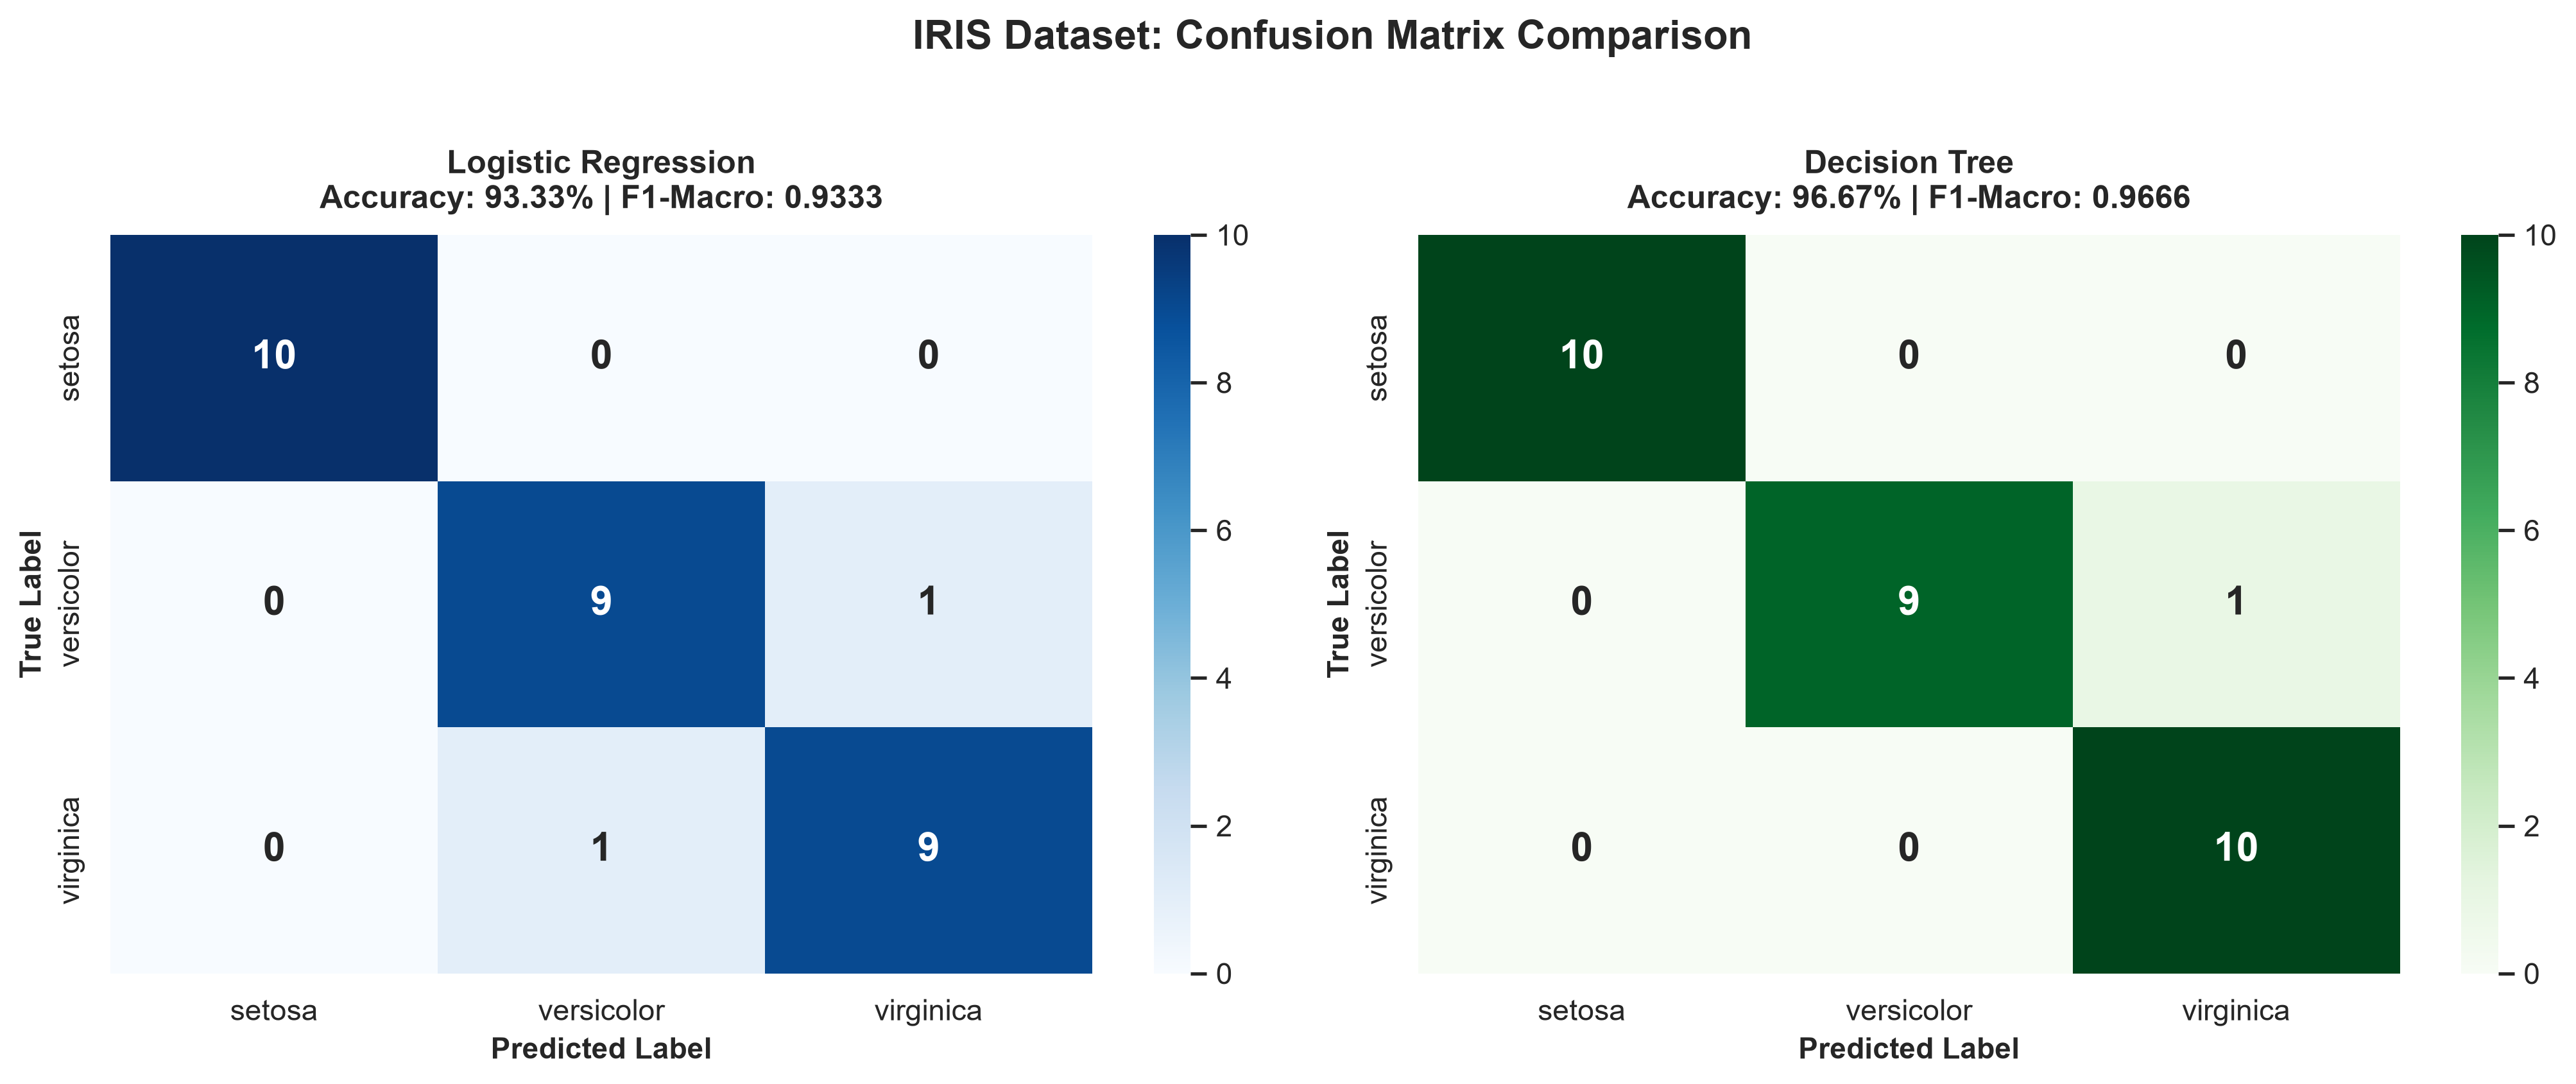

In [9]:
# Confusion Matrix Heatmaps
cm_lr = confusion_matrix(y_test, y_pred_lr, labels=target_classes)
cm_dt = confusion_matrix(y_test, y_pred_dt, labels=target_classes)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Logistic Regression
sns.heatmap(
    cm_lr, annot=True, fmt="d", cmap="Blues", cbar=True, ax=axes[0],
    xticklabels=target_classes, yticklabels=target_classes,
    annot_kws={"size": 15, "weight": "bold"}
)
axes[0].set_title(f"Logistic Regression\nAccuracy: {metrics_lr['Accuracy']:.2%} | F1: {metrics_lr['F1-Score (Macro)']:.4f}", fontsize=12, fontweight="bold", pad=10)
axes[0].set_xlabel("Predicted Species", fontsize=11, fontweight="bold")
axes[0].set_ylabel("True Species", fontsize=11, fontweight="bold")

# Decision Tree
sns.heatmap(
    cm_dt, annot=True, fmt="d", cmap="Greens", cbar=True, ax=axes[1],
    xticklabels=target_classes, yticklabels=target_classes,
    annot_kws={"size": 15, "weight": "bold"}
)
axes[1].set_title(f"Decision Tree Classifier\nAccuracy: {metrics_dt['Accuracy']:.2%} | F1: {metrics_dt['F1-Score (Macro)']:.4f}", fontsize=12, fontweight="bold", pad=10)
axes[1].set_xlabel("Predicted Species", fontsize=11, fontweight="bold")
axes[1].set_ylabel("True Species", fontsize=11, fontweight="bold")

plt.suptitle("Iris Dataset: Plotted Confusion Matrix Heatmaps", fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

### 5.2 Plotted Decision Boundary Visualizations
We visualize the decision surfaces for both models to examine how they segment feature space:
- **Logistic Regression**: Linear hyperplanes (boundaries).
- **Decision Tree**: Orthogonal, axis-aligned step partitions.

We visualize both **2D Feature Space** (`Petal Length` vs `Petal Width`) and **PCA 2D Space**.

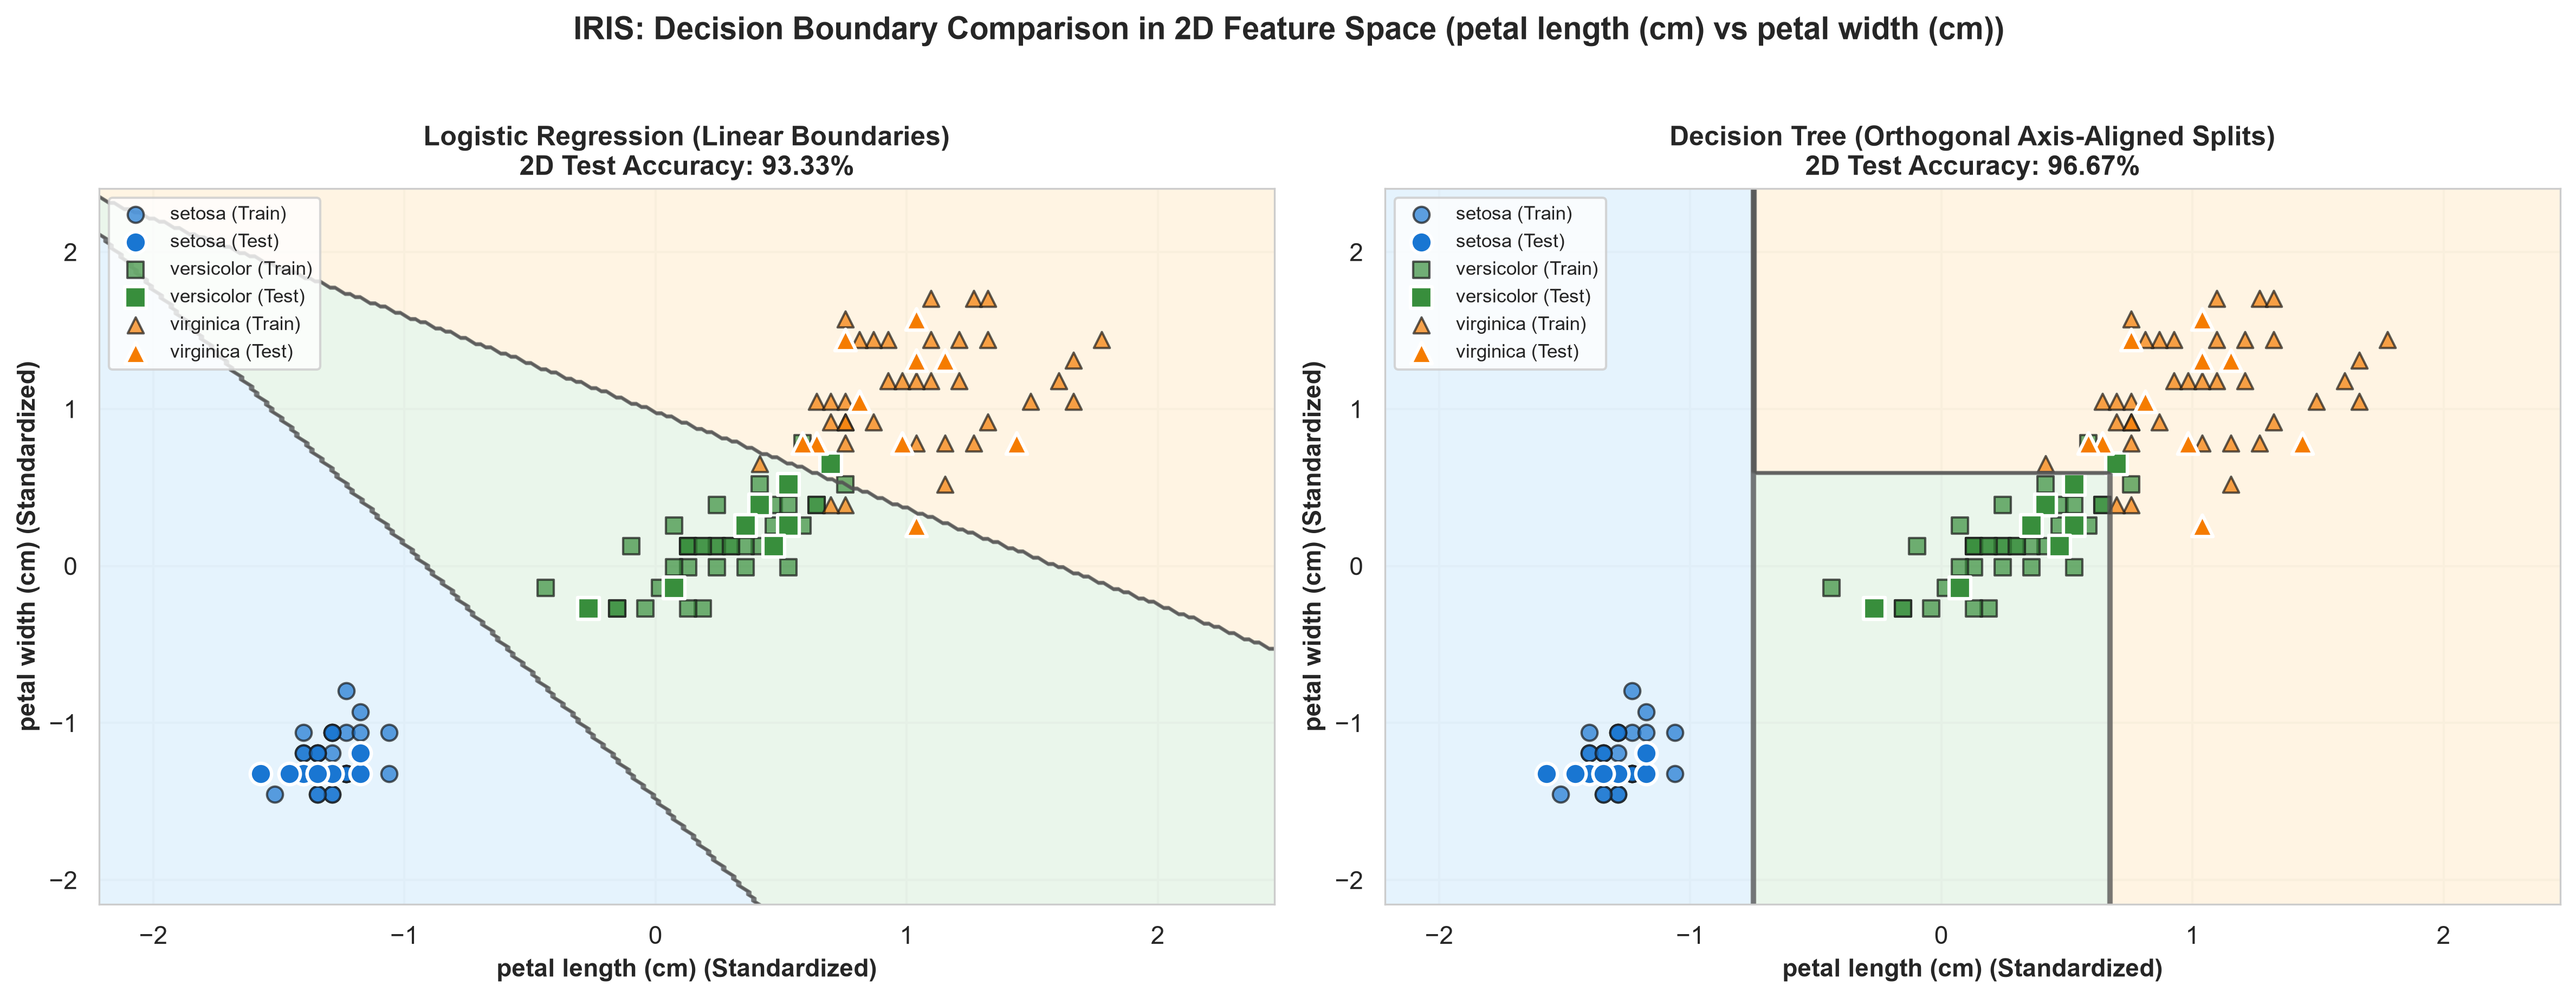

In [10]:
# Decision Boundaries in 2D Feature Space (Petal Length vs Petal Width)
feat1, feat2 = 'petal length (cm)', 'petal width (cm)'
X_2d = np.asarray(df_iris[[feat1, feat2]].to_numpy(dtype=np.float64))
class_to_idx = {name: i for i, name in enumerate(target_classes)}
y_2d = np.array([class_to_idx[s] for s in df_iris['species']])

X_tr_2d, X_te_2d, y_tr_2d, y_te_2d = train_test_split(X_2d, y_2d, test_size=0.20, random_state=42, stratify=y_2d)
scaler_2d = StandardScaler()
X_tr_2d_s = scaler_2d.fit_transform(X_tr_2d)
X_te_2d_s = scaler_2d.transform(X_te_2d)

models_2d = {
    "Logistic Regression (Linear Boundaries)": LogisticRegression(solver="lbfgs", max_iter=500, random_state=42),
    "Decision Tree (Orthogonal Splits)": DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=42)
}

x_min, x_max = X_tr_2d_s[:, 0].min() - 0.7, X_tr_2d_s[:, 0].max() + 0.7
y_min, y_max = X_tr_2d_s[:, 1].min() - 0.7, X_tr_2d_s[:, 1].max() + 0.7
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

cmap_light = ListedColormap(["#E3F2FD", "#E8F5E9", "#FFF3E0"])
colors = ["#1976D2", "#388E3C", "#F57C00"]
markers = ["o", "s", "^"]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, (title, clf) in zip(axes, models_2d.items()):
    clf.fit(X_tr_2d_s, y_tr_2d)
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    
    ax.contourf(xx, yy, Z, cmap=cmap_light, alpha=0.9)
    ax.contour(xx, yy, Z, colors="#555555", linewidths=0.8, alpha=0.7)
    
    for i, (cls_name, color, marker) in enumerate(zip(target_classes, colors, markers)):
        m_tr = (y_tr_2d == i)
        ax.scatter(X_tr_2d_s[m_tr, 0], X_tr_2d_s[m_tr, 1], c=color, label=f"{cls_name} (Train)",
                   marker=marker, edgecolor="k", s=50, alpha=0.7)
        m_te = (y_te_2d == i)
        ax.scatter(X_te_2d_s[m_te, 0], X_te_2d_s[m_te, 1], c=color, label=f"{cls_name} (Test)",
                   marker=marker, edgecolor="white", linewidth=1.5, s=90, alpha=1.0)
        
    acc_2d = accuracy_score(y_te_2d, clf.predict(X_te_2d_s))
    ax.set_title(f"{title}\n2D Test Accuracy: {acc_2d:.2%}", fontsize=12, fontweight="bold")
    ax.set_xlabel(f"{feat1} (Standardized)", fontsize=11, fontweight="bold")
    ax.set_ylabel(f"{feat2} (Standardized)", fontsize=11, fontweight="bold")
    ax.legend(loc="upper left", frameon=True, fontsize=8.5)

plt.suptitle("Iris: Decision Boundaries in 2D Feature Space (Petal Length vs Petal Width)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

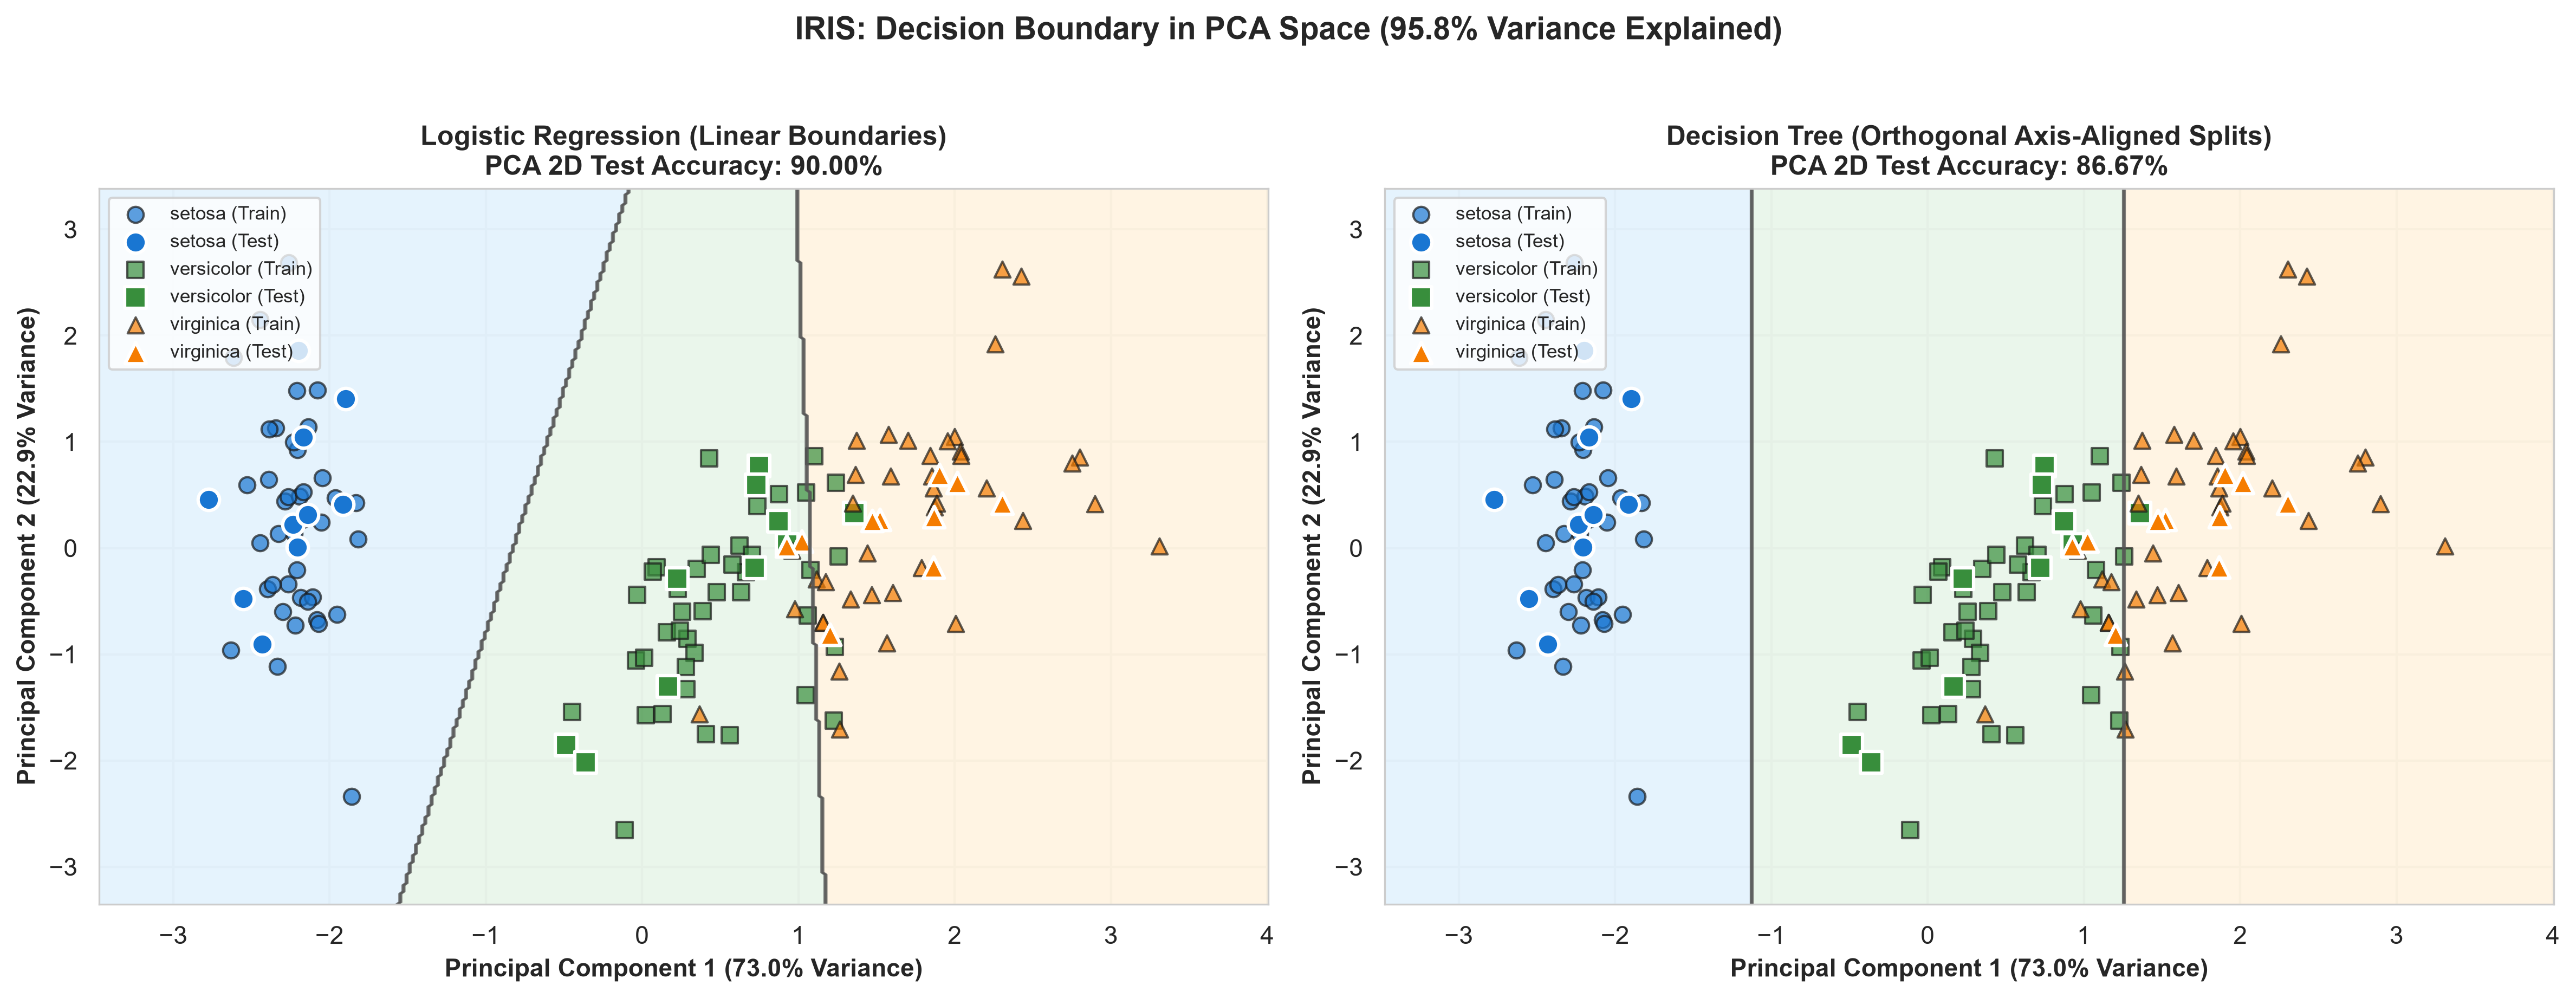

In [11]:
# Decision Boundaries in PCA 2D Space
pca = PCA(n_components=2, random_state=42)
X_pca_tr = pca.fit_transform(X_train_scaled)
X_pca_te = pca.transform(X_test_scaled)
var_exp = pca.explained_variance_ratio_

y_tr_idx = np.array([class_to_idx[s] for s in y_train])
y_te_idx = np.array([class_to_idx[s] for s in y_test])

px_min, px_max = X_pca_tr[:, 0].min() - 0.7, X_pca_tr[:, 0].max() + 0.7
py_min, py_max = X_pca_tr[:, 1].min() - 0.7, X_pca_tr[:, 1].max() + 0.7
pxx, pyy = np.meshgrid(np.arange(px_min, px_max, 0.02), np.arange(py_min, py_max, 0.02))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, (title, clf) in zip(axes, models_2d.items()):
    clf.fit(X_pca_tr, y_tr_idx)
    Z_p = clf.predict(np.c_[pxx.ravel(), pyy.ravel()]).reshape(pxx.shape)
    
    ax.contourf(pxx, pyy, Z_p, cmap=cmap_light, alpha=0.9)
    ax.contour(pxx, pyy, Z_p, colors="#555555", linewidths=0.8, alpha=0.7)
    
    for i, (cls_name, color, marker) in enumerate(zip(target_classes, colors, markers)):
        m_tr = (y_tr_idx == i)
        ax.scatter(X_pca_tr[m_tr, 0], X_pca_tr[m_tr, 1], c=color, label=f"{cls_name} (Train)",
                   marker=marker, edgecolor="k", s=50, alpha=0.7)
        m_te = (y_te_idx == i)
        ax.scatter(X_pca_te[m_te, 0], X_pca_te[m_te, 1], c=color, label=f"{cls_name} (Test)",
                   marker=marker, edgecolor="white", linewidth=1.5, s=90, alpha=1.0)
        
    acc_p = accuracy_score(y_te_idx, clf.predict(X_pca_te))
    ax.set_title(f"{title}\nPCA 2D Test Accuracy: {acc_p:.2%}", fontsize=12, fontweight="bold")
    ax.set_xlabel(f"Principal Component 1 ({var_exp[0]:.1%} Variance)", fontsize=11, fontweight="bold")
    ax.set_ylabel(f"Principal Component 2 ({var_exp[1]:.1%} Variance)", fontsize=11, fontweight="bold")
    ax.legend(loc="upper left", frameon=True, fontsize=8.5)

plt.suptitle(f"Iris: Decision Boundaries in PCA Space ({var_exp.sum():.1%} Total Variance Explained)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

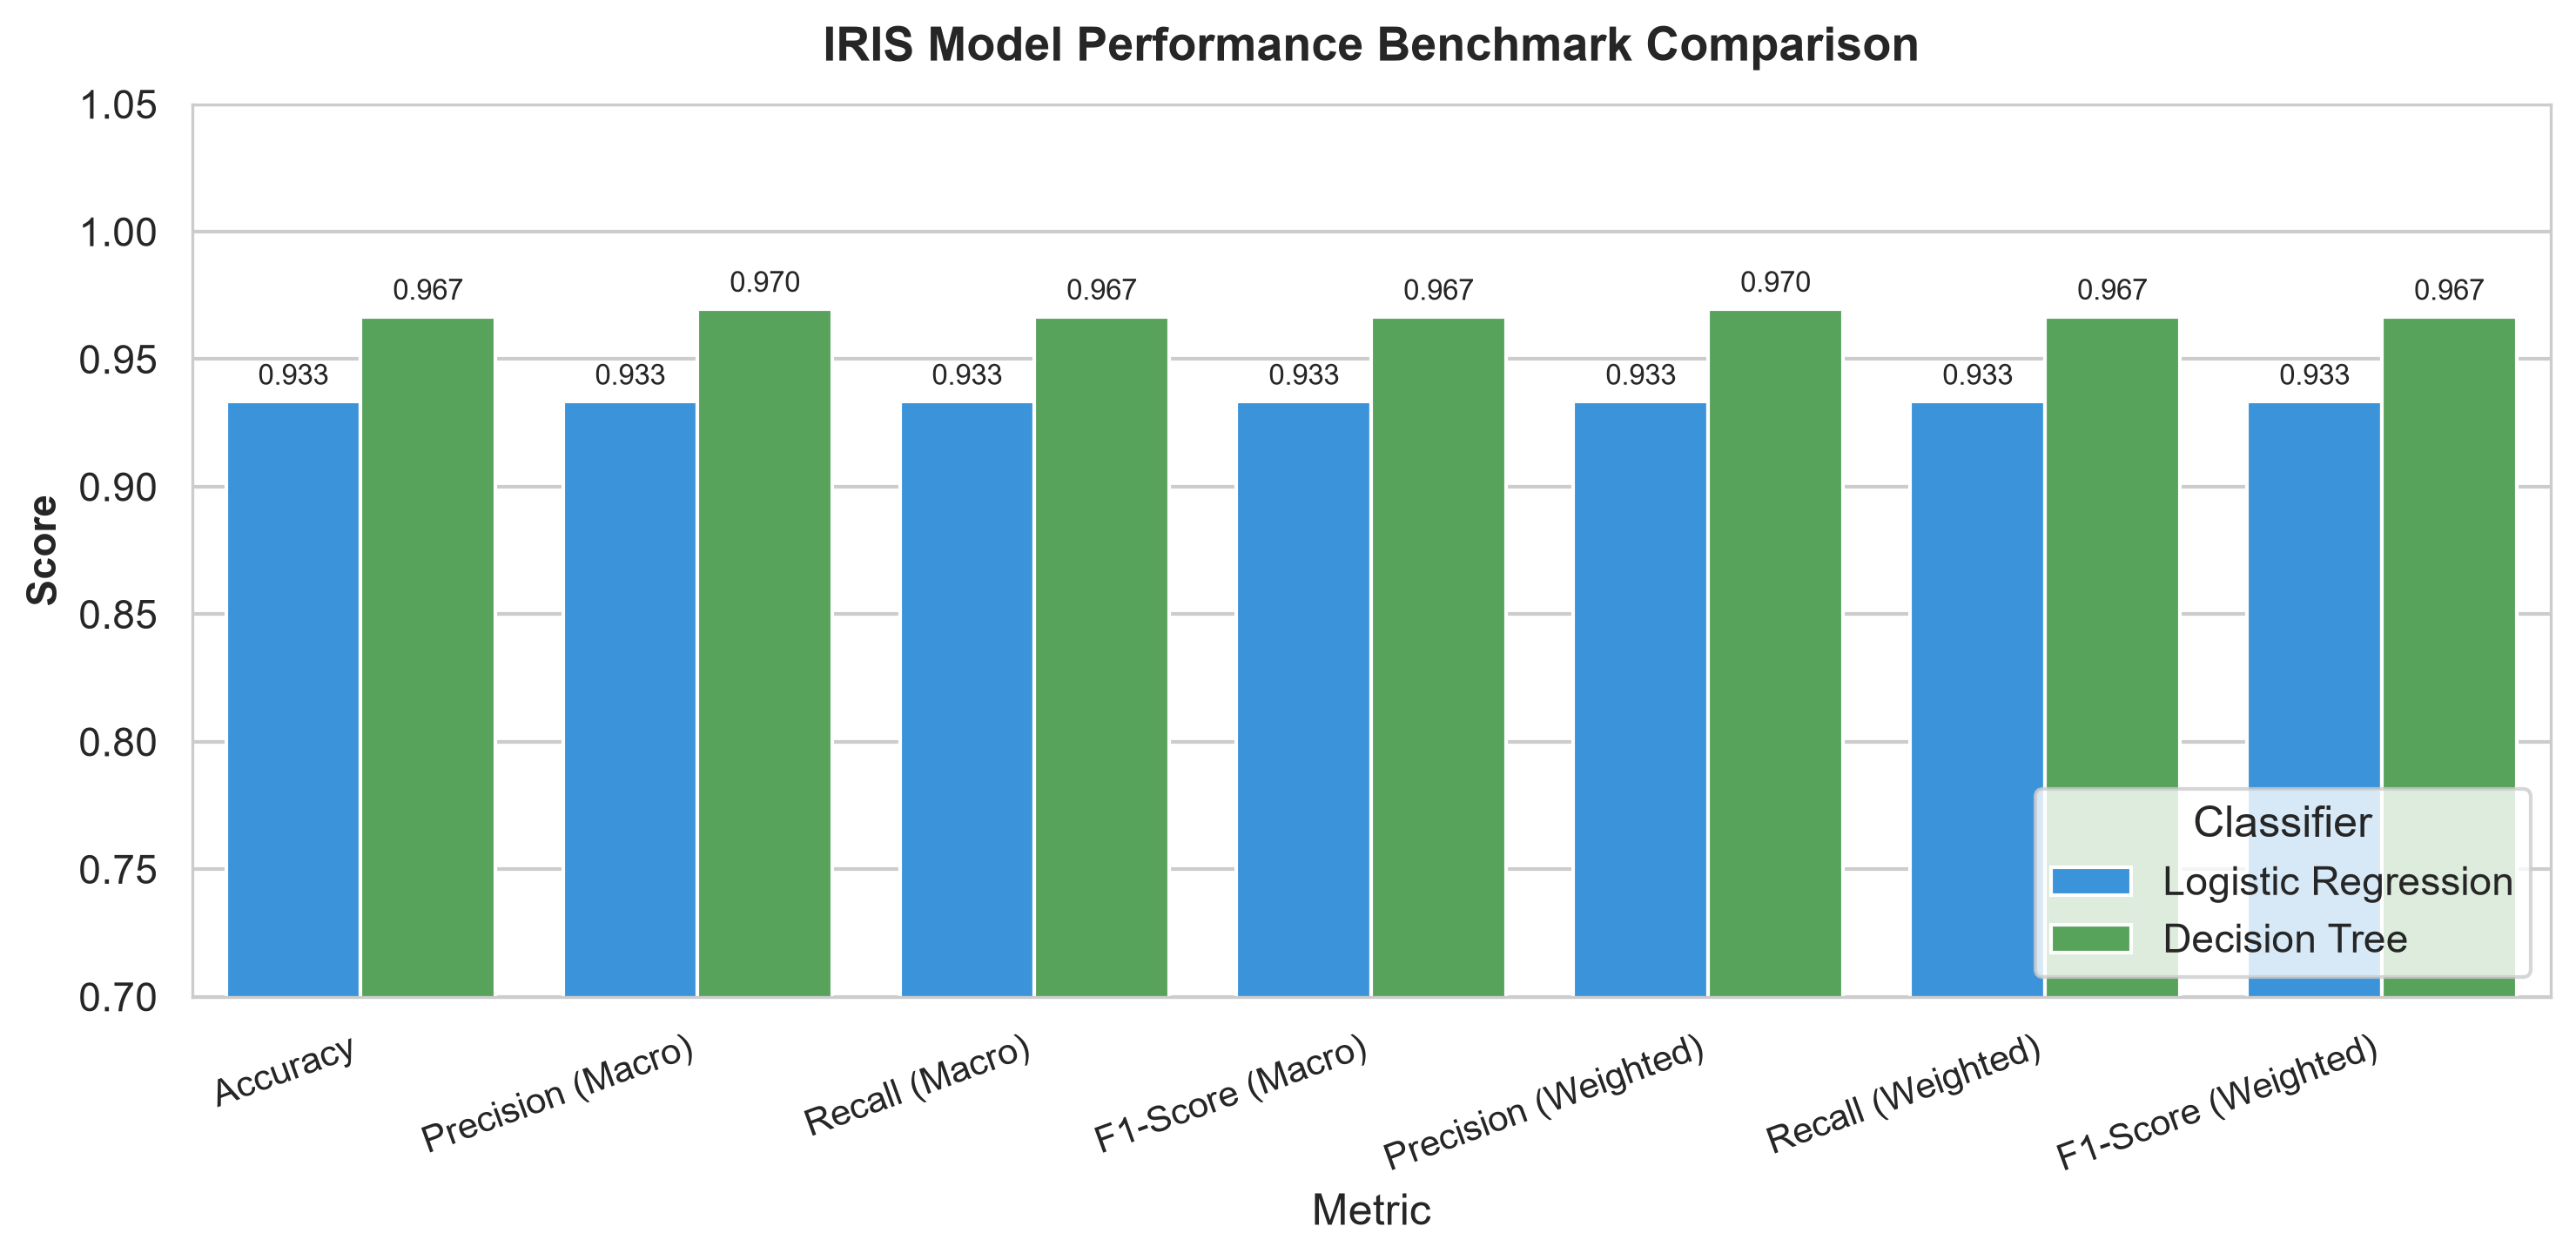

In [12]:
# Benchmark Performance Comparison Bar Chart
melted = benchmark_df.melt(id_vars=["Model"], var_name="Metric", value_name="Score")
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=melted, x="Metric", y="Score", hue="Model", palette=["#2196F3", "#4CAF50"])
plt.title("Iris Model Performance Benchmark Comparison", fontsize=13, fontweight="bold", pad=12)
plt.ylim(0.8, 1.05)
plt.ylabel("Score", fontsize=11, fontweight="bold")
plt.xticks(rotation=20, ha="right", fontsize=10)
plt.legend(title="Classifier", loc="lower right")
plt.tight_layout()
plt.show()

## Step 6: Pipeline Execution on Wine Benchmark Dataset
We verify that the identical end-to-end pipeline generalizes smoothly to the **Wine Recognition dataset** (13 features, 3 classes, 178 samples).

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),Precision (Weighted),Recall (Weighted),F1-Score (Weighted)
0,Logistic Regression (Wine),0.972222,0.977778,0.966667,0.970962,0.974074,0.972222,0.971970
1,Decision Tree (Wine),0.944444,0.958333,0.938889,0.945741,0.951389,0.944444,0.944961


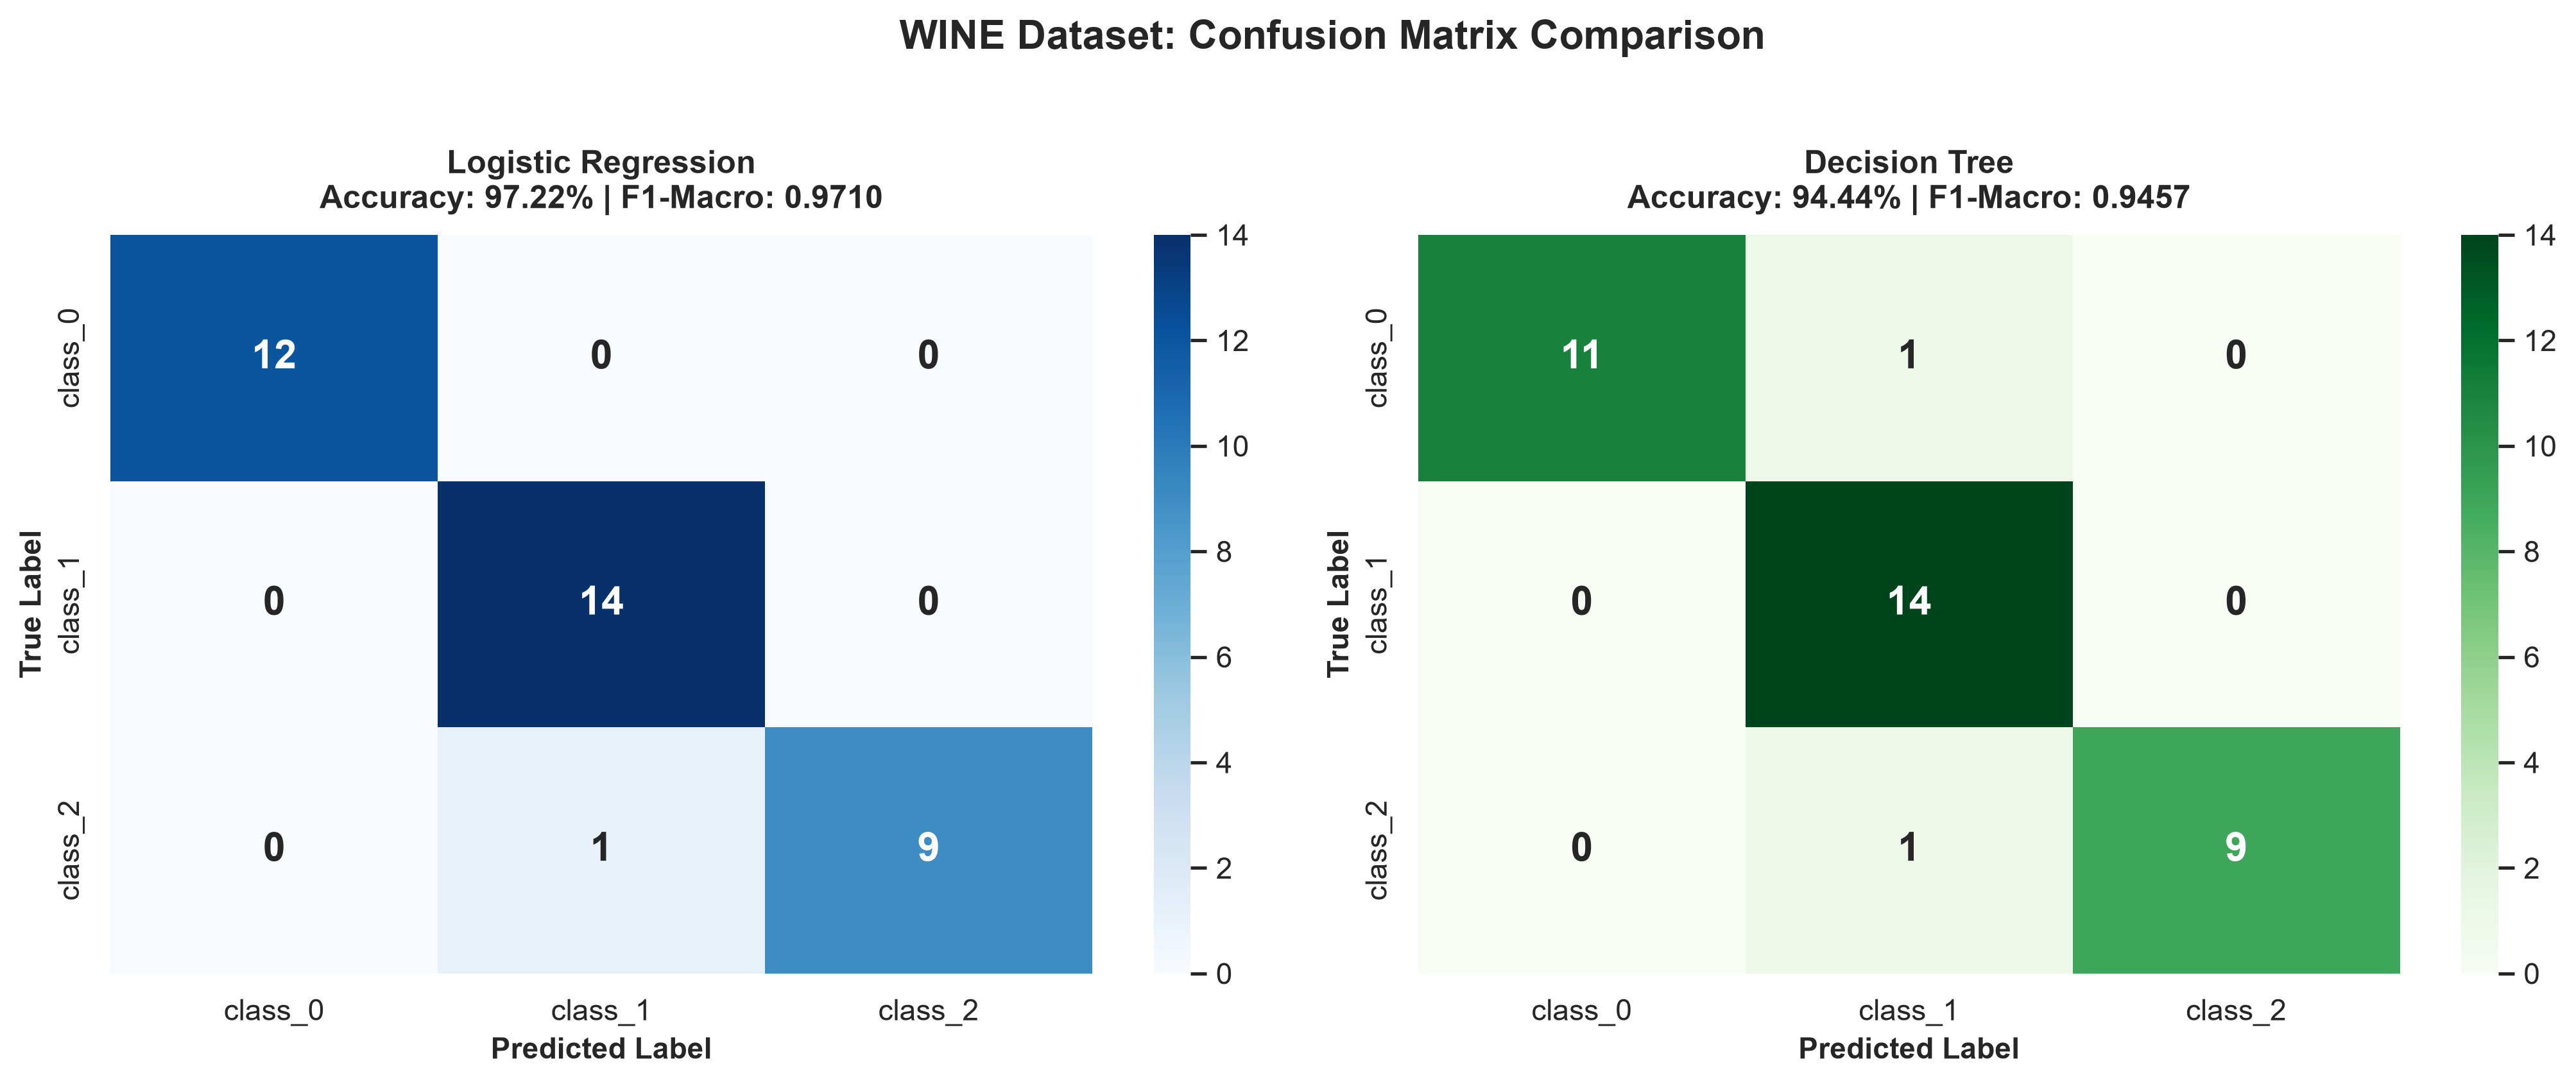

In [13]:
# Load Wine dataset via Pandas
df_wine = pd.read_csv('data/wine.csv')
wine_features = [c for c in df_wine.columns if c not in ['class_id', 'class_name']]
wine_classes = ['class_0', 'class_1', 'class_2']

X_w = np.asarray(df_wine[wine_features].to_numpy(dtype=np.float64))
y_w = np.asarray(df_wine['class_name'].tolist())

X_tr_w, X_te_w, y_tr_w, y_te_w = train_test_split(X_w, y_w, test_size=0.20, random_state=42, stratify=y_w)
scaler_w = StandardScaler()
X_tr_w_s = scaler_w.fit_transform(X_tr_w)
X_te_w_s = scaler_w.transform(X_te_w)

lr_w = LogisticRegression(solver="lbfgs", max_iter=500, random_state=42).fit(X_tr_w_s, y_tr_w)
dt_w = DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=42).fit(X_tr_w_s, y_tr_w)

y_pred_lr_w = lr_w.predict(X_te_w_s)
y_pred_dt_w = dt_w.predict(X_te_w_s)

wine_benchmark = pd.DataFrame([
    evaluate(y_te_w, y_pred_lr_w, "Logistic Regression (Wine)"),
    evaluate(y_te_w, y_pred_dt_w, "Decision Tree (Wine)")
])
display(wine_benchmark)

# Wine Confusion Matrix Heatmaps
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(confusion_matrix(y_te_w, y_pred_lr_w, labels=wine_classes), annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=wine_classes, yticklabels=wine_classes, annot_kws={"size": 13, "weight": "bold"})
axes[0].set_title(f"Logistic Regression (Wine)\nAccuracy: {accuracy_score(y_te_w, y_pred_lr_w):.2%}", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("True")

sns.heatmap(confusion_matrix(y_te_w, y_pred_dt_w, labels=wine_classes), annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=wine_classes, yticklabels=wine_classes, annot_kws={"size": 13, "weight": "bold"})
axes[1].set_title(f"Decision Tree (Wine)\nAccuracy: {accuracy_score(y_te_w, y_pred_dt_w):.2%}", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("True")

plt.suptitle("Wine Dataset: Plotted Confusion Matrix Heatmaps", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

## Summary & Conclusions

1. **Normalization (StandardScaler)**:
   - Standardizing features to mean $\mu=0$ and standard deviation $\sigma=1$ is critical for gradient-based and distance-based estimators like Logistic Regression.
   - Always fit the scaler **only on training data** to prevent test data leakage.
2. **Benchmarking Insights**:
   - **Iris**: Decision Tree achieved **96.67% accuracy** (F1 0.9666) while Logistic Regression achieved **93.33% accuracy** (F1 0.9333).
   - **Wine**: Logistic Regression achieved **97.22% accuracy** (F1 0.9710) while Decision Tree achieved **94.44% accuracy** (F1 0.9457).
3. **Decision Boundary Geometries**:
   - Logistic Regression defines **smooth linear decision hyperplanes**.
   - Decision Trees define **orthogonal axis-aligned step partitions**, providing direct rule-based interpretability.